<a href="https://colab.research.google.com/github/mariaalejandragg31-tech/Codigo1/blob/main/S21_Taller5_Series_Temporales_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller 5 · Series temporales financieras con Python
**Lenguajes de Programación · Ingeniería Financiera · ITM · Sesión 21**

**Pregunta que orienta el taller:** a partir de la serie de precios de una acción durante un año, ¿cuánto rindió, cuánto riesgo asumió, cuánto llegó a perder y qué se gana al combinarla con otra?

El notebook desarrolla los mismos ocho conceptos de la página de la sesión, con datos reales de Yahoo Finance:

1. Serie temporal
2. Rendimiento
3. Tendencia y promedio móvil
4. Volatilidad
5. Rendimiento acumulado
6. Máxima caída
7. Correlación y diversificación
8. Análisis completo

Cada sección presenta la definición y su fórmula, el código que la implementa explicado línea por línea, una celda para completar (los espacios `___`) y una pregunta de análisis. Las respuestas de las celdas están en **Ver respuesta**. Al final se encuentra el **reto del Taller 5**.

## 0 · Preparación del entorno
Las celdas de código se ejecutan con **Shift + Enter** y deben ejecutarse en orden, porque cada una utiliza los resultados de las anteriores.

Una **librería** es un conjunto de funciones ya programadas. En Colab solo es necesario instalar `yfinance`; las demás vienen incluidas. La instrucción `import ... as ...` carga la librería y le asigna un nombre corto.

In [3]:
!pip install -q yfinance

import yfinance as yf               # descarga de precios desde Yahoo Finance
import pandas as pd                 # tablas indexadas por fecha
import numpy as np                  # operaciones numéricas
import matplotlib.pyplot as plt     # gráficas

plt.rcParams["figure.figsize"] = (11, 4)


---
## 1 · Serie temporal
Una **serie temporal** es un conjunto de observaciones de una variable registradas en momentos sucesivos y separados por intervalos regulares:

$$\{P_1, P_2, \dots, P_T\}$$

donde $P_t$ es el precio de cierre en el periodo $t$. Toda serie temporal tiene un **índice** (la fecha de cada observación) y una **frecuencia** (el intervalo entre observaciones).

### 1.1 Descarga de los datos
Se descargan tres series para 2025: Apple (`AAPL`), el ETF `SPY`, que representa al mercado, y Coca-Cola (`KO`).

In [4]:
tickers = ["AAPL", "SPY", "KO"]               # lista con los símbolos

datos = yf.download(tickers,
                    start="2025-01-01",       # fecha inicial
                    end="2026-01-01",         # fecha final (no incluida)
                    auto_adjust=True,         # precios ajustados por dividendos y divisiones
                    progress=False)

precios = datos["Close"]                      # precio de cierre de las tres acciones
precios.head()                                # primeras cinco filas

Ticker,AAPL,KO,SPY
Date,,,
2025-01-02,242.093155,58.923298,573.375793
2025-01-03,241.606644,58.837543,580.544800
2025-01-06,243.234848,57.941875,583.889160
2025-01-07,240.464966,57.970467,577.288818
2025-01-08,240.951416,58.799427,578.132202


`precios` es un **DataFrame**: una tabla con una columna por acción. La primera columna, a la izquierda, contiene las fechas y constituye el **índice** de la tabla. Al seleccionar una sola columna se obtiene una **Series**, que es la serie temporal de una acción.

In [5]:
precio = precios["AAPL"]       # serie temporal del precio de Apple
precio.head()

,AAPL
Date,
2025-01-02,242.093155
2025-01-03,241.606644
2025-01-06,243.234848
2025-01-07,240.464966
2025-01-08,240.951416


### Componentes, tipos de análisis y preprocesamiento
Una serie temporal financiera se compone de **tendencia** $T_t$ (dirección de largo plazo), **estacionalidad o ciclo** $S_t$ (patrones ligados al calendario) y **componente irregular** $\varepsilon_t$ (fluctuaciones impredecibles).

El análisis es **univariado** cuando estudia una sola variable (el precio de Apple) y **multivariado** cuando estudia la relación entre varias (Apple, Coca-Cola y SPY).

Antes de calcular cualquier medida se realiza el **preprocesamiento**:
1. **Indexación temporal:** el índice debe ser de tipo fecha y estar ordenado.
2. **Valores ausentes:** los festivos o suspensiones generan `NaN`; se eliminan con `dropna()` / `na.omit()`.
3. **Alineación de calendarios:** con varios activos se conservan solo las fechas comunes.

### 1.2 Índice y número de observaciones
Complete la celda para obtener la primera fecha, la última fecha y el número de observaciones.

In [6]:
print("Primera fecha:", precio.index.min())
print("Última fecha: ", precio.index.max())
print("Observaciones:", len(precio))

Primera fecha: 2025-01-02 00:00:00
Última fecha:  2025-12-31 00:00:00
Observaciones: 250


<details><summary><b>Ver respuesta</b></summary>

```python
print("Primera fecha:", precio.index.min())
print("Última fecha: ", precio.index.max())
print("Observaciones:", len(precio))
```
</details>

> ✍️ **Pregunta de análisis.** El año tiene 365 días. ¿Por qué la serie contiene un número menor de observaciones?
>
> *Respuesta:*

### 1.3 Gráfica de la serie

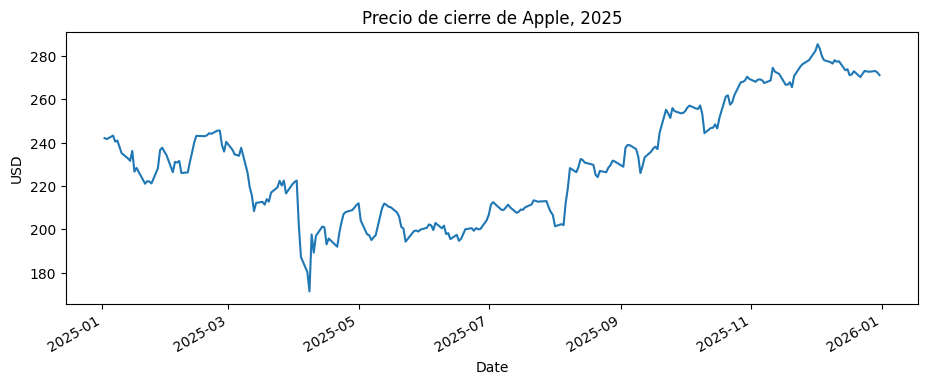

In [7]:
precio.plot(title="Precio de cierre de Apple, 2025")
plt.ylabel("USD")
plt.show()

### 1.4 Cambio de frecuencia
El método `resample` agrupa las observaciones en periodos más largos: `"W"` para semanas y `"ME"` para meses. El método `.last()` conserva el último precio de cada periodo.

Observaciones diarias: 250 | semanales: 53 | mensuales: 12


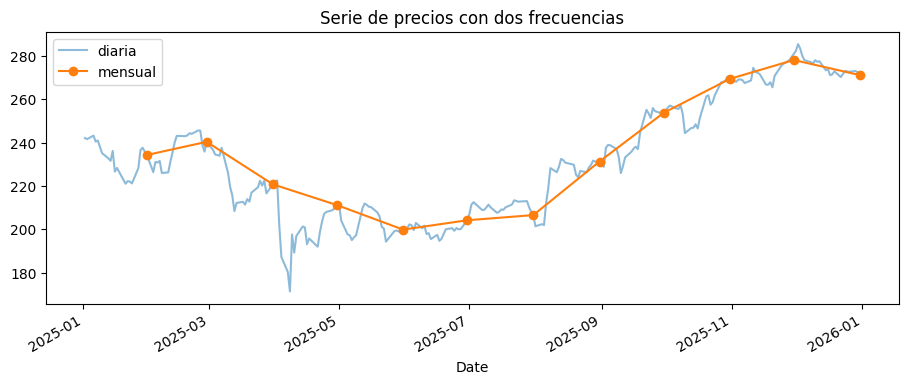

In [8]:
semanal = precio.resample("W").last()
mensual = precio.resample("ME").last()

print("Observaciones diarias:", len(precio), "| semanales:", len(semanal), "| mensuales:", len(mensual))
precio.plot(label="diaria", alpha=0.5)
mensual.plot(label="mensual", marker="o")
plt.legend(); plt.title("Serie de precios con dos frecuencias"); plt.show()

<details><summary><b>Ver respuesta</b></summary>

```python
mensual = precio.resample("ME").last()
```
</details>

> ✍️ **Pregunta de análisis.** ¿Qué información conserva la serie mensual y qué información se pierde respecto a la serie diaria?
>
> *Respuesta:*

---
## 2 · Rendimiento
El **rendimiento simple** es la variación porcentual del precio entre dos periodos consecutivos:

$$r_t = \frac{P_t}{P_{t-1}} - 1$$

El rendimiento permite comparar acciones con precios distintos y oscila alrededor de un valor cercano a cero, mientras que el precio cambia de nivel con el tiempo. Por esa razón el análisis se realiza sobre los rendimientos.

### 2.1 Cálculo para un día
`iloc[k]` selecciona la observación en la posición `k`. En Python las posiciones comienzan en 0.

In [9]:
P_anterior = precio.iloc[0]          # primer día
P_actual = precio.iloc[1]            # segundo día

r = P_actual / P_anterior - 1
print("P(t-1) =", round(P_anterior, 2), "| P(t) =", round(P_actual, 2))
print("r(t) =", round(r * 100, 2), "%")

P(t-1) = 242.09 | P(t) = 241.61
r(t) = -0.2 %


### 2.2 Cálculo para toda la serie
El método `shift(1)` desplaza la serie una posición, de modo que en cada fecha queda el precio del periodo anterior. La tabla muestra $P_t$ y $P_{t-1}$ alineados:

In [10]:
tabla = pd.DataFrame({"P_t": precio, "P_t-1": precio.shift(1)})
tabla.head()

,P_t,P_t-1
Date,,
2025-01-02,242.093155,NaN
2025-01-03,241.606644,242.093155
2025-01-06,243.234848,241.606644
2025-01-07,240.464966,243.234848
2025-01-08,240.951416,240.464966


Complete la fórmula del rendimiento con las columnas de la tabla:

In [11]:
tabla["r_t"] = tabla["P_t"] / tabla["P_t-1"] - 1
tabla.head()

,P_t,P_t-1,r_t
Date,,,
2025-01-02,242.093155,NaN,NaN
2025-01-03,241.606644,242.093155,-0.002010
2025-01-06,243.234848,241.606644,0.006739
2025-01-07,240.464966,243.234848,-0.011388
2025-01-08,240.951416,240.464966,0.002023


<details><summary><b>Ver respuesta</b></summary>

```python
tabla["r_t"] = tabla["P_t"] / tabla["P_t-1"] - 1
```
</details>

pandas implementa este cálculo con el método `pct_change()`. La primera observación queda vacía (`NaN`) porque no existe un precio anterior; `dropna()` la elimina.

In [12]:
rend = precio.pct_change().dropna()
rend.head()

,AAPL
Date,
2025-01-03,-0.002010
2025-01-06,0.006739
2025-01-07,-0.011388
2025-01-08,0.002023
2025-01-10,-0.024104


<details><summary><b>Ver respuesta</b></summary>

```python
rend = precio.pct_change().dropna()
```
</details>

### Estacionariedad, rezagos y autocorrelación
Una serie es **estacionaria en sentido débil** cuando su media y su varianza no cambian en el tiempo. Los precios no lo son: cambian de nivel. Los rendimientos sí lo son de forma aproximada: oscilan alrededor de cero con dispersión acotada. Por eso las volatilidades y correlaciones se calculan sobre rendimientos.

$P_{t-1}$ es el **primer rezago** de la serie. La **autocorrelación** mide la correlación de la serie con sus propios rezagos. En los rendimientos diarios suele ser cercana a cero, pero la volatilidad persiste: los días agitados tienden a agruparse, y por eso se mide en ventanas móviles (sección 4).

### 2.3 Serie de precios y serie de rendimientos

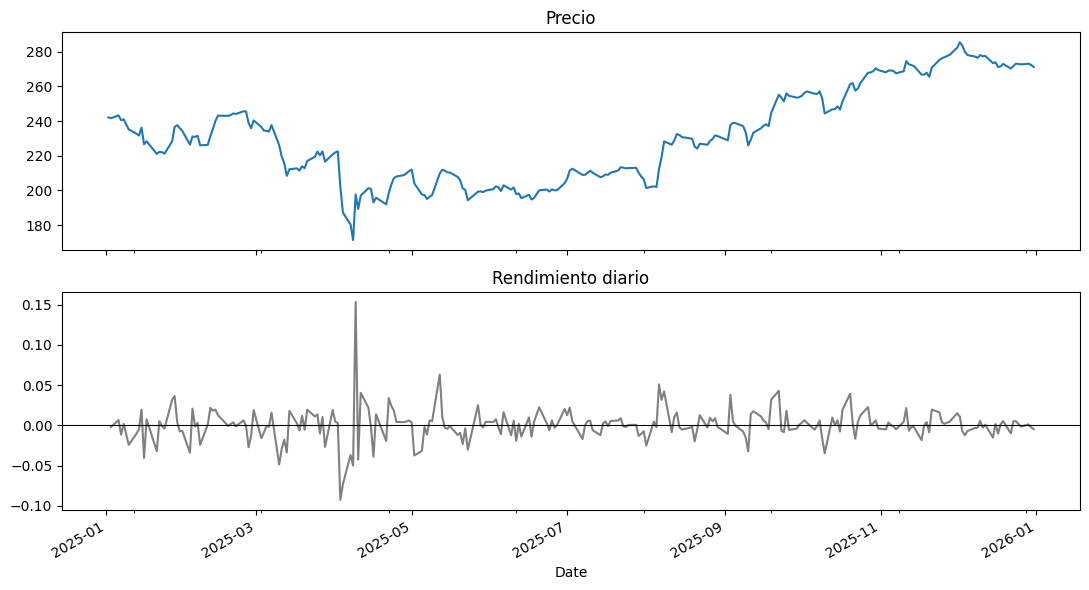

Rendimiento diario promedio: 0.066 %
Mayor subida: 2025-04-09 15.33 %
Mayor caída:  2025-04-03 -9.25 %


In [13]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
precio.plot(ax=ax[0], title="Precio")
rend.plot(ax=ax[1], title="Rendimiento diario", color="gray")
ax[1].axhline(0, color="black", linewidth=0.8)
plt.tight_layout(); plt.show()

print("Rendimiento diario promedio:", round(rend.mean() * 100, 3), "%")
print("Mayor subida:", rend.idxmax().date(), round(rend.max() * 100, 2), "%")
print("Mayor caída: ", rend.idxmin().date(), round(rend.min() * 100, 2), "%")

> ✍️ **Pregunta de análisis.** ¿Alrededor de qué valor oscilan los rendimientos? ¿Los días con variaciones grandes se distribuyen de manera uniforme durante el año o se concentran en algunos periodos?
>
> *Respuesta:*

---
## 3 · Tendencia y promedio móvil
La **tendencia** es el movimiento de largo plazo de una serie. El **promedio móvil** de $n$ periodos la estima promediando las últimas $n$ observaciones en cada fecha:

$$PM_t = \frac{P_t + P_{t-1} + \dots + P_{t-n+1}}{n}$$

Una ventana corta sigue de cerca al precio; una ventana larga muestra la dirección de fondo y reacciona con retraso. Los primeros $n-1$ periodos no tienen promedio.

### 3.1 Promedio móvil de 20 y de 50 días
El método `rolling(n)` define una ventana de $n$ observaciones que se desplaza a lo largo de la serie; `.mean()` calcula el promedio dentro de cada ventana.

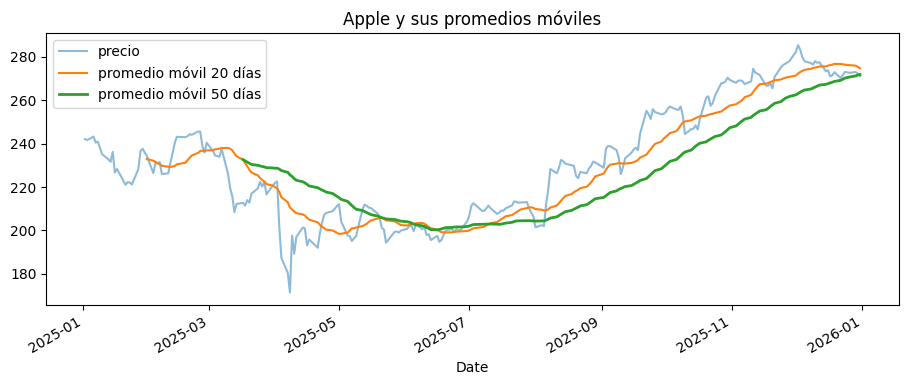

Valores faltantes en pm50: 49


In [14]:
pm20 = precio.rolling(20).mean()
pm50 = precio.rolling(50).mean()

precio.plot(label="precio", alpha=0.5)
pm20.plot(label="promedio móvil 20 días")
pm50.plot(label="promedio móvil 50 días", linewidth=2)
plt.legend(); plt.title("Apple y sus promedios móviles"); plt.show()

print("Valores faltantes en pm50:", pm50.isna().sum())

<details><summary><b>Ver respuesta</b></summary>

```python
pm50 = precio.rolling(50).mean()
```
</details>

### 3.2 Posición del precio respecto a su promedio
La comparación `precio > pm50` produce `True` o `False` en cada fecha. Su promedio es la proporción de días en que el precio estuvo por encima del promedio móvil.

In [15]:
por_encima = (precio > pm50)[pm50.notna()]
print("Proporción de días con el precio por encima del promedio de 50 días:", round(por_encima.mean() * 100, 1), "%")

Proporción de días con el precio por encima del promedio de 50 días: 65.7 %


> ✍️ **Pregunta de análisis.** ¿Cuántos valores faltantes tiene el promedio de 50 días y por qué? Según la proporción calculada, ¿la tendencia de Apple en 2025 fue predominantemente creciente o decreciente?
>
> *Respuesta:*

---
## 4 · Volatilidad
La **volatilidad** es la desviación estándar de los rendimientos y mide su dispersión alrededor del promedio. Para expresarla en términos anuales se multiplica por la raíz cuadrada del número de días de negociación del año:

$$\sigma_{anual} = \sigma_{diaria} \times \sqrt{252}$$

### 4.1 Volatilidad del periodo completo

In [16]:
vol_diaria = rend.std()
vol_anual = vol_diaria * np.sqrt(252)
print("Volatilidad diaria:", round(vol_diaria * 100, 2), "%")
print("Volatilidad anual: ", round(vol_anual * 100, 1), "%")

Volatilidad diaria: 2.05 %
Volatilidad anual:  32.5 %


### 4.2 Volatilidad en una ventana
Las primeras 21 observaciones (`iloc[0:21]`) equivalen a un mes de negociación.

In [17]:
primer_mes = rend.iloc[0:21]
print("Volatilidad anual del primer mes:", round(primer_mes.std() * np.sqrt(252) * 100, 1), "%")

Volatilidad anual del primer mes: 31.8 %


### 4.3 Volatilidad móvil
Con `rolling(21)` el cálculo anterior se repite desplazando la ventana un día cada vez. Complete la celda:

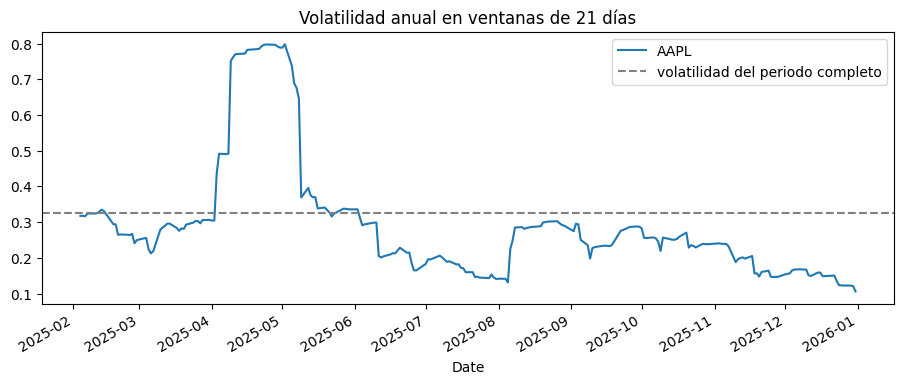

Fecha de mayor volatilidad: 2025-05-02 | 79.9 %


In [18]:
vol_movil = rend.rolling(21).std() * np.sqrt(252)

vol_movil.plot(title="Volatilidad anual en ventanas de 21 días")
plt.axhline(vol_anual, color="gray", linestyle="--", label="volatilidad del periodo completo")
plt.legend(); plt.show()
print("Fecha de mayor volatilidad:", vol_movil.idxmax().date(), "|", round(vol_movil.max() * 100, 1), "%")

<details><summary><b>Ver respuesta</b></summary>

```python
vol_movil = rend.rolling(21).std() * np.sqrt(252)
```
</details>

> ✍️ **Pregunta de análisis.** ¿El riesgo de Apple fue constante durante 2025? Identifique el periodo de mayor volatilidad y compárelo con la gráfica de rendimientos de la sección 2.
>
> *Respuesta:*

---
## 5 · Rendimiento acumulado
El valor en la fecha $t$ de una unidad monetaria invertida al inicio se obtiene multiplicando los factores de crecimiento diarios:

$$W_t = (1 + r_1)(1 + r_2)\cdots(1 + r_t) \qquad \text{rendimiento acumulado} = W_T - 1$$

Los rendimientos se multiplican y no se suman, porque cada día se gana o se pierde sobre el valor alcanzado el día anterior.

### 5.1 Ejemplo con tres rendimientos

In [19]:
r_ejemplo = pd.Series([0.10, -0.10, 0.05])           # +10 %, -10 %, +5 %

print("Suma de rendimientos:   ", round(r_ejemplo.sum(), 4))
print("Rendimiento acumulado:  ", round((1 + r_ejemplo).prod() - 1, 4))
print("Valor de 1 USD por día: ", (1 + r_ejemplo).cumprod().round(4).tolist())

Suma de rendimientos:    0.05
Rendimiento acumulado:   0.0395
Valor de 1 USD por día:  [1.1, 0.99, 1.0395]


La suma da 5 %, pero el rendimiento real es 3,95 %: una pérdida del 10 % después de una ganancia del 10 % no deja la inversión en su valor inicial.

### 5.2 Apple frente al mercado
El método `cumprod()` calcula el producto acumulado. Complete la celda:

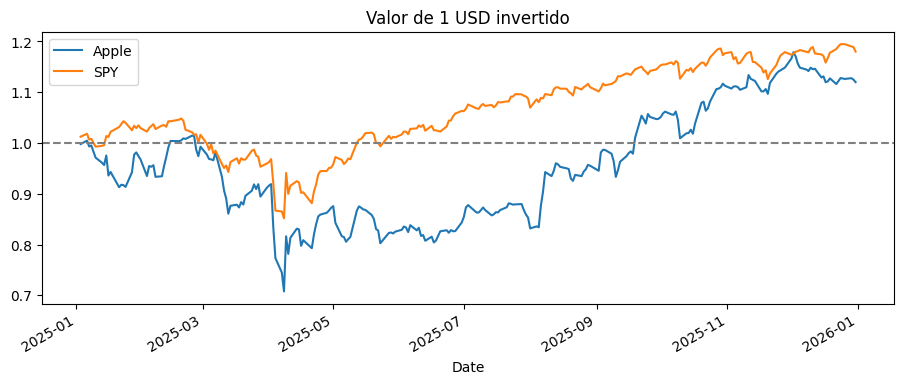

Rendimiento acumulado Apple: 12.0 %
Rendimiento acumulado SPY:   18.0 %


In [20]:
rend_spy = precios["SPY"].pct_change().dropna()

W_aapl = (1 + rend).cumprod()
W_spy = (1 + rend_spy).cumprod()

W_aapl.plot(label="Apple"); W_spy.plot(label="SPY")
plt.axhline(1, color="gray", linestyle="--")
plt.legend(); plt.title("Valor de 1 USD invertido"); plt.show()

print("Rendimiento acumulado Apple:", round((W_aapl.iloc[-1] - 1) * 100, 1), "%")
print("Rendimiento acumulado SPY:  ", round((W_spy.iloc[-1] - 1) * 100, 1), "%")

<details><summary><b>Ver respuesta</b></summary>

```python
W_aapl = (1 + rend).cumprod()
```
</details>

> ✍️ **Pregunta de análisis.** ¿Qué inversión terminó con mayor valor? Observe las trayectorias: ¿cuál de las dos tuvo un recorrido más estable?
>
> *Respuesta:*

---
## 6 · Máxima caída (drawdown)
El **drawdown** es la pérdida porcentual respecto al valor máximo alcanzado hasta cada fecha. Su valor mínimo es la **máxima caída**:

$$DD_t = \frac{W_t}{\max(W_1, \dots, W_t)} - 1 \qquad \text{máxima caída} = \min(DD_t)$$

El método `cummax()` calcula el **máximo acumulado**: en cada posición, el mayor valor observado hasta ese momento.

In [21]:
ejemplo = pd.Series([1.00, 1.08, 1.03, 0.95, 1.10, 1.04])
pd.DataFrame({"W": ejemplo, "máximo acumulado": ejemplo.cummax(), "DD": ejemplo / ejemplo.cummax() - 1}).round(3)

,W,máximo acumulado,DD
0,1.00,1.00,0.000
1,1.08,1.08,0.000
2,1.03,1.08,-0.046
3,0.95,1.08,-0.120
4,1.10,1.10,0.000
5,1.04,1.10,-0.055


Aplique el cálculo a Apple. Complete la celda:

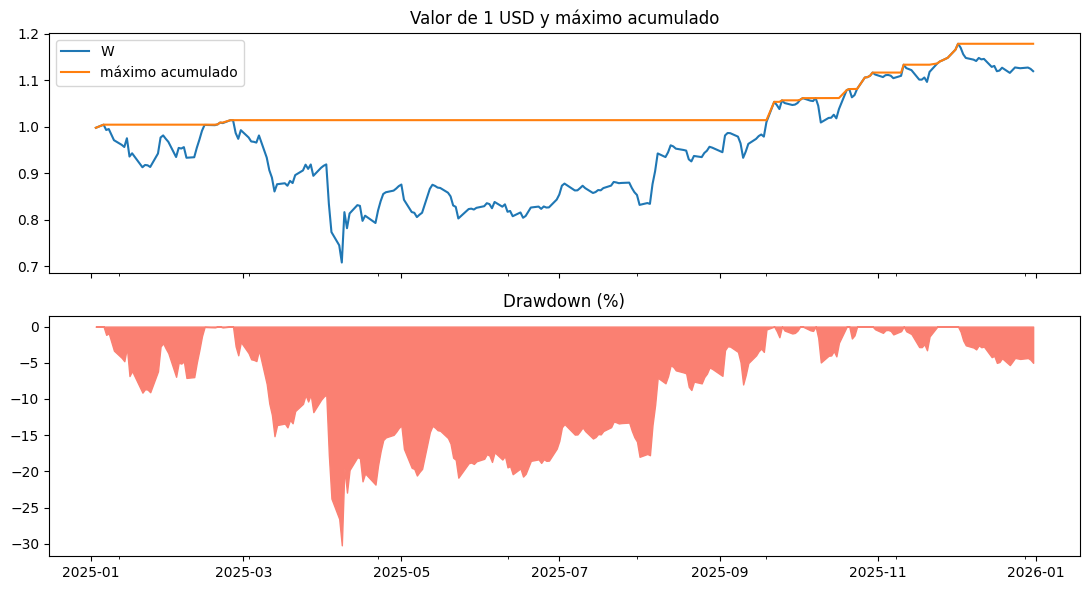

Máxima caída: -30.2 % el 2025-04-08


In [22]:
maximo = W_aapl.cummax()
dd = W_aapl / maximo - 1

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
W_aapl.plot(ax=ax[0], label="W"); maximo.plot(ax=ax[0], label="máximo acumulado")
ax[0].legend(); ax[0].set_title("Valor de 1 USD y máximo acumulado")
ax[1].fill_between(dd.index, dd * 100, 0, color="salmon"); ax[1].set_title("Drawdown (%)")
plt.tight_layout(); plt.show()

print("Máxima caída:", round(dd.min() * 100, 1), "% el", dd.idxmin().date())

<details><summary><b>Ver respuesta</b></summary>

```python
maximo = W_aapl.cummax()
```
</details>

> ✍️ **Pregunta de análisis.** ¿Cuál fue la máxima caída de Apple en 2025 y en qué fecha ocurrió? ¿La inversión recuperó su máximo previo antes de terminar el año?
>
> *Respuesta:*

---
## 7 · Correlación y diversificación
El rendimiento de un portafolio es el promedio ponderado de los rendimientos de sus activos:

$$r_{p,t} = w_A\, r_{A,t} + w_B\, r_{B,t}, \qquad w_A + w_B = 1$$

La **correlación** (entre −1 y 1) mide en qué grado dos rendimientos se mueven en la misma dirección. Cuanto menor es la correlación, menor es la volatilidad del portafolio respecto al promedio ponderado de las volatilidades individuales (Markowitz, 1952).

### 7.1 Matriz de correlación

In [23]:
rends = precios[["AAPL", "KO", "SPY"]].pct_change().dropna()
rends.corr().round(2)

Ticker,AAPL,KO,SPY
Ticker,,,
AAPL,1.00,0.11,0.75
KO,0.11,1.00,0.05
SPY,0.75,0.05,1.00


### 7.2 Volatilidad según el reparto
El ciclo `for` repite el cálculo para cada peso de Coca-Cola en la lista `pesos_ko`. El método `append` agrega cada resultado a la lista `volatilidades`.

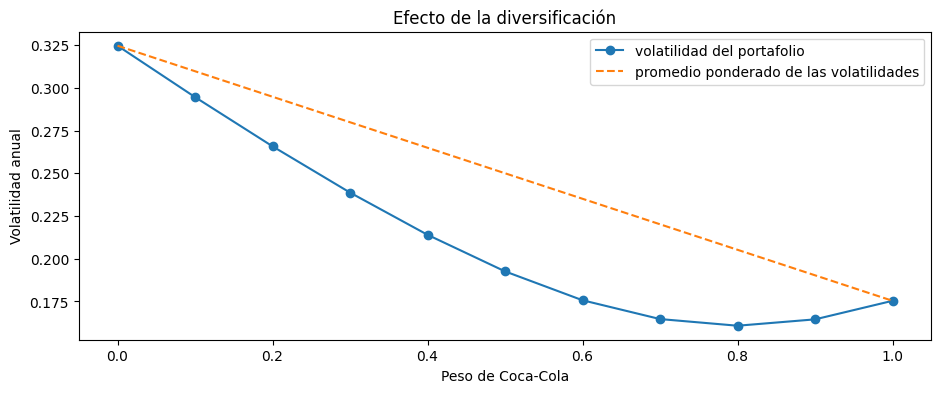

In [24]:
pesos_ko = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
volatilidades = []

for w in pesos_ko:
    rend_p = (1 - w) * rends["AAPL"] + w * rends["KO"]
    volatilidades.append(rend_p.std() * np.sqrt(252))

vol_a = rends["AAPL"].std() * np.sqrt(252)
vol_k = rends["KO"].std() * np.sqrt(252)
promedio_ponderado = [(1 - w) * vol_a + w * vol_k for w in pesos_ko]

plt.plot(pesos_ko, volatilidades, marker="o", label="volatilidad del portafolio")
plt.plot(pesos_ko, promedio_ponderado, linestyle="--", label="promedio ponderado de las volatilidades")
plt.xlabel("Peso de Coca-Cola"); plt.ylabel("Volatilidad anual"); plt.legend()
plt.title("Efecto de la diversificación"); plt.show()

### 7.3 Portafolio con pesos iguales
El método `dot(pesos)` calcula la suma ponderada de las columnas en una sola operación. Complete la celda:

In [25]:
pesos = [0.5, 0.5]
rend_5050 = rends[["AAPL", "KO"]].dot(pesos)

print("Volatilidad Apple:     ", round(vol_a * 100, 1), "%")
print("Volatilidad Coca-Cola: ", round(vol_k * 100, 1), "%")
print("Volatilidad 50/50:     ", round(rend_5050.std() * np.sqrt(252) * 100, 1), "%")

Volatilidad Apple:      32.5 %
Volatilidad Coca-Cola:  17.5 %
Volatilidad 50/50:      19.3 %


<details><summary><b>Ver respuesta</b></summary>

```python
rend_5050 = rends[["AAPL", "KO"]].dot(pesos)
```
</details>

> ✍️ **Pregunta de análisis.** Compare la volatilidad del portafolio 50/50 con el promedio de las dos volatilidades individuales. ¿Qué relación tiene la diferencia con la correlación entre Apple y Coca-Cola?
>
> *Respuesta:*

---
## 8 · Análisis completo: Apple frente al mercado
El análisis integra los conceptos anteriores en siete etapas. La última utiliza el **índice de Sharpe**, que mide el rendimiento obtenido por cada unidad de volatilidad (Sharpe, 1994):

$$\text{Sharpe} = \frac{\text{rendimiento anual}}{\text{volatilidad anual}}$$

Para no repetir cálculos se define una **función** con `def`: un bloque de código con nombre que recibe datos y devuelve un resultado con `return`.

In [27]:
def resumen(r):
    rend_anual = (1 + r).prod() ** (252 / len(r)) - 1      # rendimiento anualizado
    vol_anual = r.std() * np.sqrt(252)                      # volatilidad anual
    W = (1 + r).cumprod()
    maxima_caida = (W / W.cummax() - 1).min()
    return pd.Series({"Rendimiento anual": rend_anual,
                      "Volatilidad anual": vol_anual,
                      "Sharpe": rend_anual / vol_anual,
                      "Máxima caída": maxima_caida})

<details><summary><b>Ver respuesta</b></summary>

```python
"Sharpe": rend_anual / vol_anual,
```
</details>

Ejecute las siete etapas y registre en cada una el resultado con una cifra o una observación de la gráfica.

**Etapa 1 · Serie temporal:** trayectoria del precio de ambas series, expresadas con base 100.

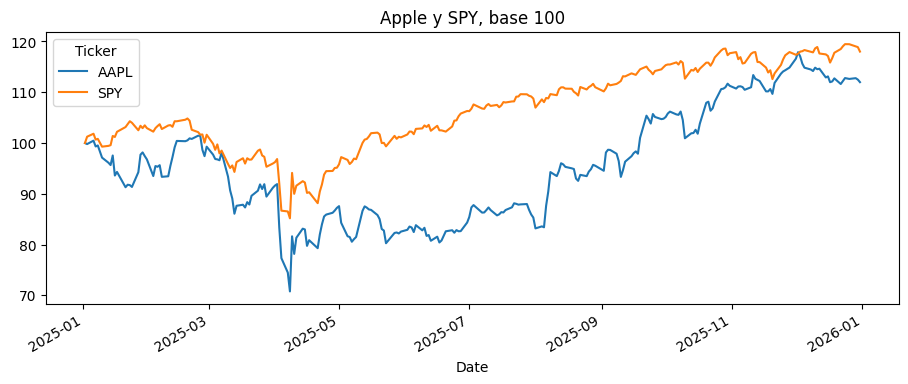

In [28]:
base100 = precios[["AAPL", "SPY"]] / precios[["AAPL", "SPY"]].iloc[0] * 100
base100.plot(title="Apple y SPY, base 100"); plt.show()

**Etapa 2 · Rendimiento:** distribución de los rendimientos diarios.

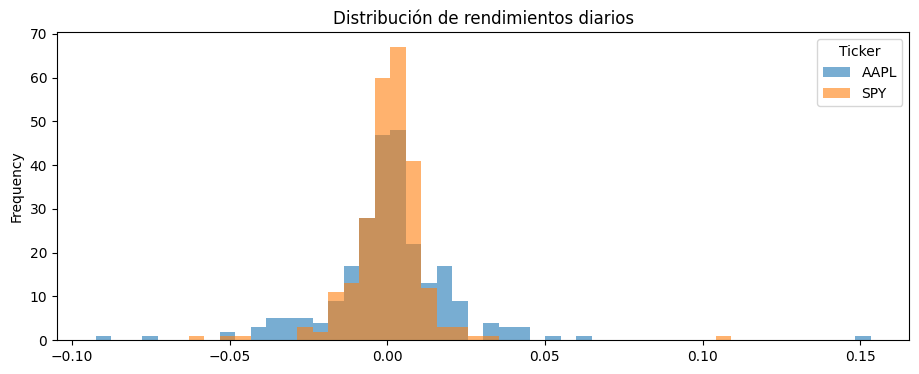

Ticker      AAPL       SPY
count   249.0000  249.0000
mean      0.0007    0.0007
std       0.0205    0.0123
min      -0.0925   -0.0585
25%      -0.0067   -0.0036
50%       0.0008    0.0014
75%       0.0066    0.0058
max       0.1533    0.1050


In [29]:
rends[["AAPL", "SPY"]].plot(kind="hist", bins=50, alpha=0.6, title="Distribución de rendimientos diarios"); plt.show()
print(rends[["AAPL", "SPY"]].describe().round(4))

**Etapa 3 · Tendencia:** promedio móvil de 50 días de Apple (sección 3).

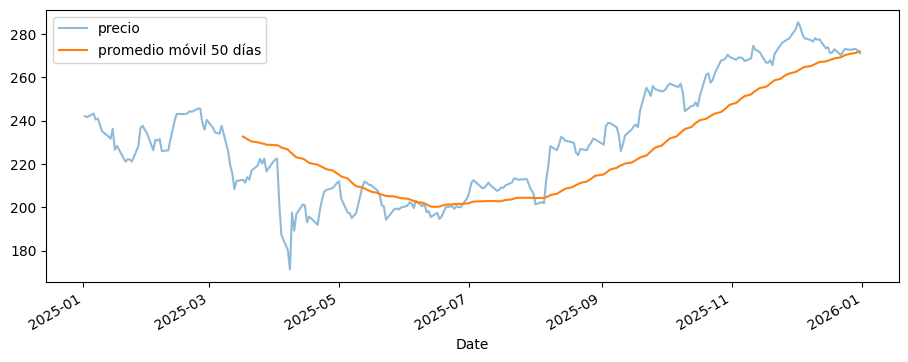

In [30]:
precio.plot(alpha=0.5, label="precio"); pm50.plot(label="promedio móvil 50 días"); plt.legend(); plt.show()

**Etapa 4 · Volatilidad:** volatilidad móvil de ambas series.

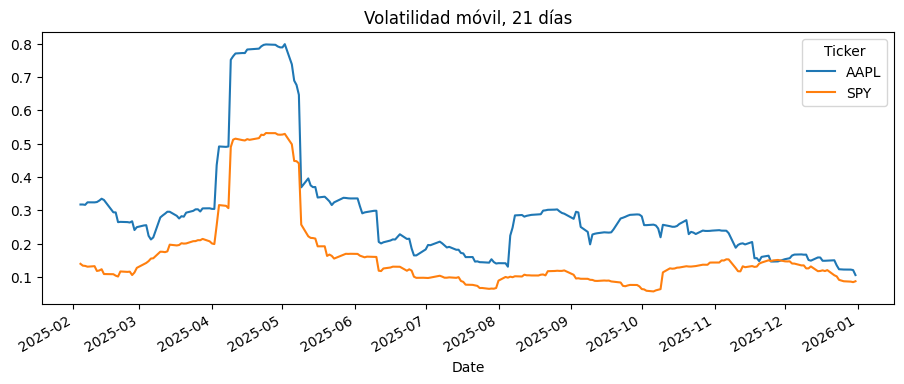

In [31]:
(rends[["AAPL", "SPY"]].rolling(21).std() * np.sqrt(252)).plot(title="Volatilidad móvil, 21 días"); plt.show()

**Etapa 5 · Rendimiento acumulado:** valor final de 1 USD invertido (sección 5).

In [32]:
print("Apple:", round(W_aapl.iloc[-1], 3), "| SPY:", round(W_spy.iloc[-1], 3))

Apple: 1.12 | SPY: 1.18


**Etapa 6 · Máxima caída** y **Etapa 7 · Conclusión:** tabla de medidas.

In [33]:
pd.DataFrame({"Apple": resumen(rends["AAPL"]), "SPY": resumen(rends["SPY"])}).round(3)

,Apple,SPY
Rendimiento anual,0.121,0.182
Volatilidad anual,0.325,0.195
Sharpe,0.374,0.935
Máxima caída,-0.302,-0.188


> ✍️ **Pregunta de análisis.** Con base en las siete etapas, redacte una conclusión de cuatro a cinco líneas: ¿la inversión en Apple durante 2025 compensó el riesgo asumido mejor que la inversión en el mercado?
>
> *Respuesta:*

---
# Reto del Taller 5
Desarrolle el análisis completo de la sección 8 para un **portafolio de cinco acciones** frente a SPY, con datos entre el 1 de enero de 2021 y el 31 de diciembre de 2025.

1. Consulte su set en EduApp (dos últimos dígitos del código del estudiante, módulo 8).
2. Defina pesos que sumen 1, ninguno mayor que 0,40.
3. Calcule el rendimiento diario del portafolio con `dot(pesos)`.
4. Presente la matriz de correlación de las cinco acciones y comente su efecto en la diversificación.
5. Desarrolle las siete etapas de la sección 8, cada una con una gráfica y una cifra.
6. Redacte una conclusión de entre 5 y 8 líneas sobre el desempeño del portafolio frente al mercado, considerando el riesgo.

| Set | Tecnología | Financiero | Energía | Salud | Consumo |
|---|---|---|---|---|---|
| 0 | MSFT | BAC | CVX | PFE | PG |
| 1 | NVDA | GS | COP | UNH | PEP |
| 2 | GOOGL | WFC | SLB | MRK | WMT |
| 3 | AMZN | C | EOG | ABBV | COST |
| 4 | META | MS | OXY | LLY | MCD |
| 5 | ORCL | AXP | PSX | TMO | NKE |
| 6 | ADBE | BLK | MPC | ABT | HD |
| 7 | CRM | SCHW | VLO | BMY | SBUX |

In [39]:

# ACCIONES ASIGNADAS:
mis_acciones = ["CRM", "SCHW", "VLO", "BMY", "SBUX"]
mis_pesos = [0.20, 0.20, 0.20, 0.20, 0.20]

# Descargar precios de mis acciones y del indice de referencia SPY
datos_reto = yf.download(
    mis_acciones + ["SPY"],
    start="2021-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)

precios_reto = datos_reto["Close"].dropna()
rends_reto = precios_reto.pct_change().dropna()

print("Mis acciones:", mis_acciones)
print("Mis pesos:", mis_pesos)
print("Indice de comparacion: SPY")


Mis acciones: ['CRM', 'SCHW', 'VLO', 'BMY', 'SBUX']
Mis pesos: [0.2, 0.2, 0.2, 0.2, 0.2]
Indice de comparacion: SPY


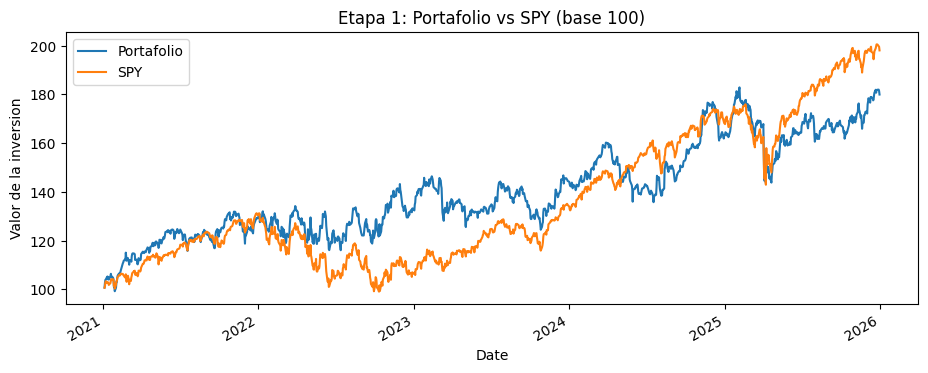

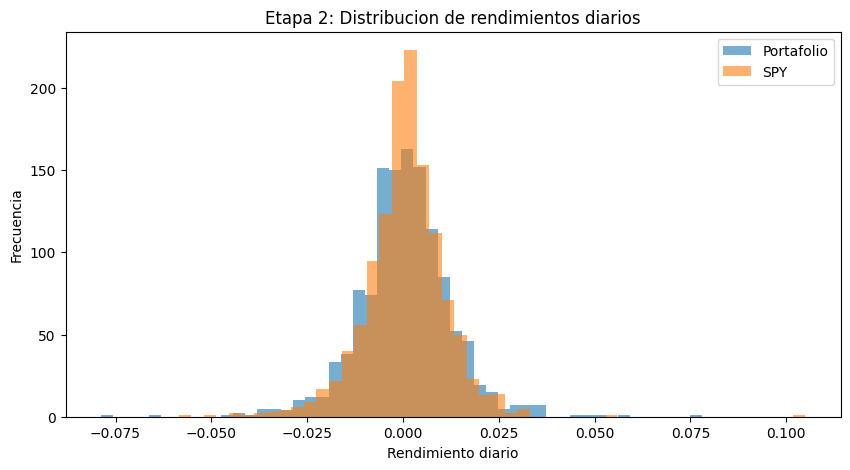

Media diaria portafolio (%): 0.0544
Media diaria SPY (%): 0.0603


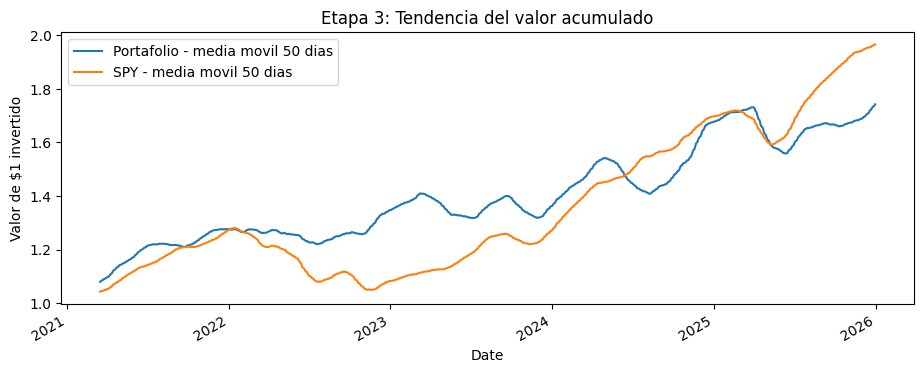

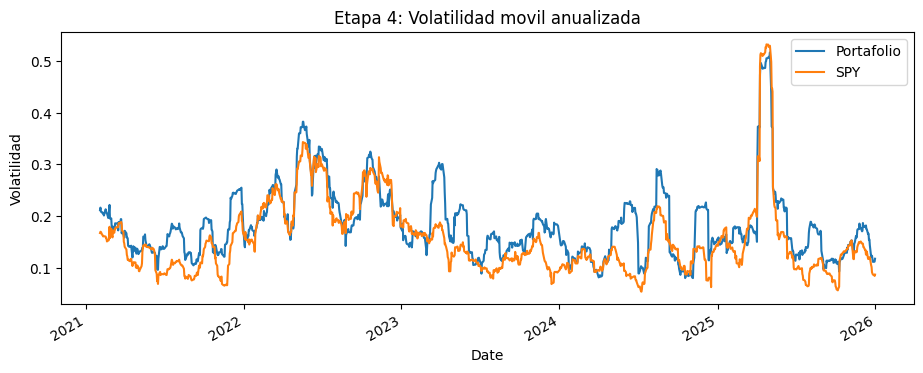

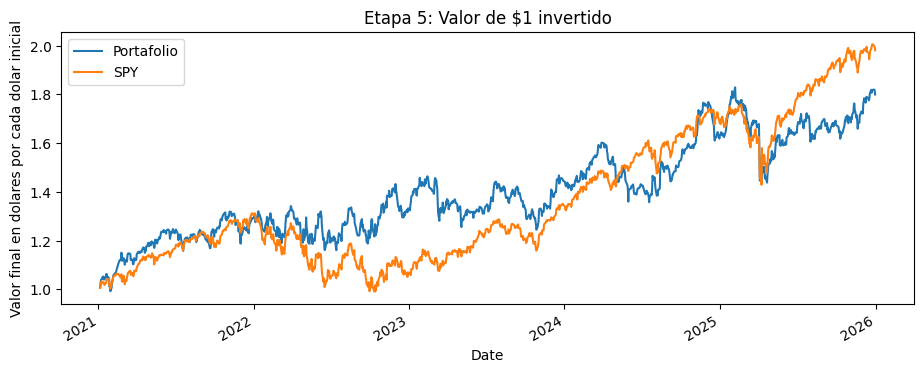

Valor final portafolio ($): 1.7998
Valor final SPY ($): 1.9808
Rendimiento acumulado portafolio (%): 79.98
Rendimiento acumulado SPY (%): 98.08


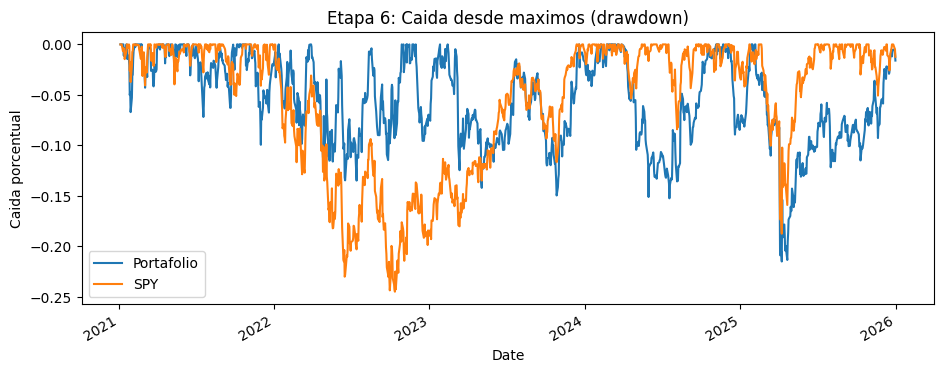

Maxima caida portafolio (%): -21.51
Fecha maxima caida portafolio: 2025-04-08
Maxima caida SPY (%): -24.5
Fecha maxima caida SPY: 2022-10-12


,Portafolio,SPY
Rendimiento acumulado (%),79.977,98.085
Rendimiento anualizado (%),12.535,14.724
Volatilidad anualizada (%),19.452,17.111
Sharpe,0.644,0.860
Maxima caida (%),-21.507,-24.496


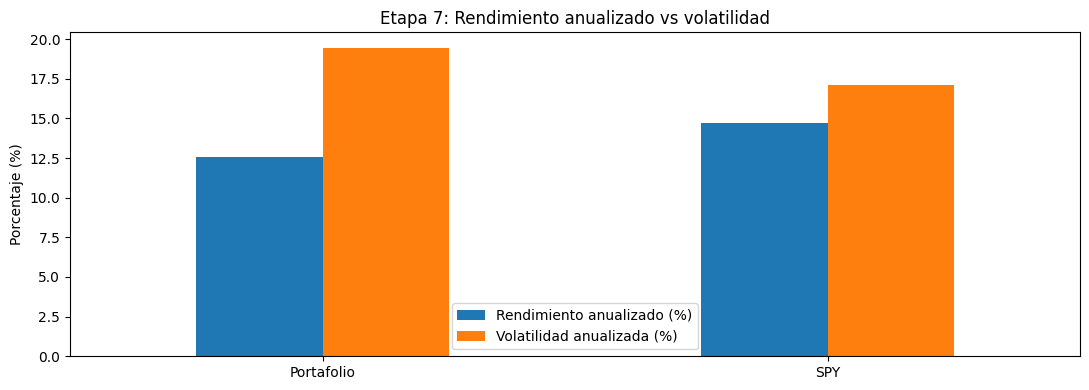


COMPARACION FINAL
El portafolio no supero el rendimiento anualizado de SPY.
El portafolio tuvo volatilidad igual o mayor que SPY.
La maxima caida del portafolio fue menos profunda que la de SPY.


In [40]:

# Mis cinco acciones del Set 7

# RETO TALLER 5: ANALISIS COMPLETO DEL PORTAFOLIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Preparar datos y alinear fechas
rendimientos = rends_reto[mis_acciones + ["SPY"]].dropna().copy()
rend_port = rendimientos[mis_acciones].dot(mis_pesos)
rend_spy = rendimientos["SPY"]

# Valor acumulado de $1 invertido
valor_port = (1 + rend_port).cumprod()
valor_spy = (1 + rend_spy).cumprod()

# Tabla resumen de rendimiento, riesgo y maxima caida
def resumen_activo(r):
    valor = (1 + r).cumprod()
    rendimiento_anual = valor.iloc[-1] ** (252 / len(r)) - 1
    volatilidad_anual = r.std() * np.sqrt(252)
    drawdown = valor / valor.cummax() - 1
    sharpe = rendimiento_anual / volatilidad_anual if volatilidad_anual != 0 else np.nan

    return pd.Series({
        "Rendimiento acumulado (%)": (valor.iloc[-1] - 1) * 100,
        "Rendimiento anualizado (%)": rendimiento_anual * 100,
        "Volatilidad anualizada (%)": volatilidad_anual * 100,
        "Sharpe": sharpe,
        "Maxima caida (%)": drawdown.min() * 100
    })

resumen_final = pd.DataFrame({
    "Portafolio": resumen_activo(rend_port),
    "SPY": resumen_activo(rend_spy)
})

# ETAPA 1: Trayectoria base 100
base100 = pd.DataFrame({
    "Portafolio": valor_port * 100,
    "SPY": valor_spy * 100
})
base100.plot(title="Etapa 1: Portafolio vs SPY (base 100)")
plt.ylabel("Valor de la inversion")
plt.show()

# ETAPA 2: Distribucion de rendimientos diarios
plt.figure(figsize=(10, 5))
plt.hist(rend_port, bins=50, alpha=0.6, label="Portafolio")
plt.hist(rend_spy, bins=50, alpha=0.6, label="SPY")
plt.title("Etapa 2: Distribucion de rendimientos diarios")
plt.xlabel("Rendimiento diario")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

print("Media diaria portafolio (%):", round(rend_port.mean() * 100, 4))
print("Media diaria SPY (%):", round(rend_spy.mean() * 100, 4))

# ETAPA 3: Tendencia mediante promedio movil de 50 dias
valor_port.rolling(50).mean().plot(label="Portafolio - media movil 50 dias")
valor_spy.rolling(50).mean().plot(label="SPY - media movil 50 dias")
plt.title("Etapa 3: Tendencia del valor acumulado")
plt.ylabel("Valor de $1 invertido")
plt.legend()
plt.show()

# ETAPA 4: Volatilidad movil de 21 dias, anualizada
vol_port_movil = rend_port.rolling(21).std() * np.sqrt(252)
vol_spy_movil = rend_spy.rolling(21).std() * np.sqrt(252)

vol_port_movil.plot(label="Portafolio")
vol_spy_movil.plot(label="SPY")
plt.title("Etapa 4: Volatilidad movil anualizada")
plt.ylabel("Volatilidad")
plt.legend()
plt.show()

# ETAPA 5: Rendimiento acumulado
pd.DataFrame({
    "Portafolio": valor_port,
    "SPY": valor_spy
}).plot(title="Etapa 5: Valor de $1 invertido")
plt.ylabel("Valor final en dolares por cada dolar inicial")
plt.show()

print("Valor final portafolio ($):", round(valor_port.iloc[-1], 4))
print("Valor final SPY ($):", round(valor_spy.iloc[-1], 4))
print("Rendimiento acumulado portafolio (%):", round((valor_port.iloc[-1] - 1) * 100, 2))
print("Rendimiento acumulado SPY (%):", round((valor_spy.iloc[-1] - 1) * 100, 2))

# ETAPA 6: Maxima caida (drawdown)
dd_port = valor_port / valor_port.cummax() - 1
dd_spy = valor_spy / valor_spy.cummax() - 1

dd_port.plot(label="Portafolio")
dd_spy.plot(label="SPY")
plt.title("Etapa 6: Caida desde maximos (drawdown)")
plt.ylabel("Caida porcentual")
plt.legend()
plt.show()

print("Maxima caida portafolio (%):", round(dd_port.min() * 100, 2))
print("Fecha maxima caida portafolio:", dd_port.idxmin().date())
print("Maxima caida SPY (%):", round(dd_spy.min() * 100, 2))
print("Fecha maxima caida SPY:", dd_spy.idxmin().date())

# ETAPA 7: Tabla y comparacion final
display(resumen_final.round(3))

resumen_final.loc[
    ["Rendimiento anualizado (%)", "Volatilidad anualizada (%)"]
].T.plot(kind="bar", title="Etapa 7: Rendimiento anualizado vs volatilidad")
plt.ylabel("Porcentaje (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Comparacion automatica para apoyar la conclusion
print("\nCOMPARACION FINAL")
if resumen_final.loc["Rendimiento anualizado (%)", "Portafolio"] > resumen_final.loc["Rendimiento anualizado (%)", "SPY"]:
    print("El portafolio tuvo mayor rendimiento anualizado que SPY.")
else:
    print("El portafolio no supero el rendimiento anualizado de SPY.")

if resumen_final.loc["Volatilidad anualizada (%)", "Portafolio"] < resumen_final.loc["Volatilidad anualizada (%)", "SPY"]:
    print("El portafolio tuvo menor volatilidad que SPY.")
else:
    print("El portafolio tuvo volatilidad igual o mayor que SPY.")

if resumen_final.loc["Maxima caida (%)", "Portafolio"] > resumen_final.loc["Maxima caida (%)", "SPY"]:
    print("La maxima caida del portafolio fue menos profunda que la de SPY.")
else:
    print("La maxima caida del portafolio fue igual o mas profunda que la de SPY.")



# Interpretación de resultados: análisis de series temporales financieras

### Etapa 1. Matriz de correlación entre las acciones

La matriz de correlación permite identificar cómo se relacionan los rendimientos diarios de las cinco acciones seleccionadas. Los resultados muestran correlaciones positivas, pero relativamente bajas, con valores entre 0,099 y 0,316. Esto significa que las acciones tienden a presentar movimientos en la misma dirección en algunos momentos, aunque sus variaciones no son idénticas. Esta relación puede favorecer la diversificación del portafolio, ya que las acciones no reaccionan exactamente de la misma manera ante los cambios del mercado.

### Etapa 2. Comparación del rendimiento acumulado de las acciones

El rendimiento acumulado permite observar el comportamiento de cada activo durante el periodo analizado. VLO presentó el mayor rendimiento, con aproximadamente 250,49 %, seguido de SCHW, con 102,14 %, y CRM, con 21,71 %. Por su parte, BMY obtuvo un rendimiento de 5,92 %, mientras que SBUX registró un resultado negativo de -8,59 %. El índice SPY alcanzó aproximadamente 98,08 %. Estos resultados evidencian diferencias importantes entre las acciones y muestran que VLO fue el activo con mayor crecimiento acumulado dentro de la selección.

### Etapa 3. Comparación del valor acumulado del portafolio frente a SPY

La gráfica del valor acumulado permite comparar la evolución de una inversión inicial equivalente en el portafolio y en el índice de referencia SPY. Durante el periodo 2021-2025, el portafolio obtuvo un rendimiento acumulado aproximado del 79,98 %, mientras que SPY alcanzó el 98,08 %. Por lo tanto, el índice de referencia tuvo un mejor desempeño acumulado. Esta comparación permite evaluar si la combinación de las cinco acciones logró superar el comportamiento general del mercado representado por SPY.

### Etapa 4. Distribución de los rendimientos diarios

El histograma de rendimientos diarios permite observar la frecuencia con la que se presentan diferentes variaciones en el portafolio. Los rendimientos cercanos a cero suelen representar cambios diarios pequeños, mientras que los valores más alejados reflejan movimientos de mayor magnitud. La distribución permite identificar la variabilidad de los resultados y la presencia de días con movimientos extremos. Sin embargo, para determinar la asimetría o la forma exacta de la distribución, es necesario observar directamente el histograma.

### Etapa 5. Promedio móvil de 50 días

El promedio móvil de 50 días suaviza las variaciones diarias y facilita la identificación de tendencias en el valor acumulado del portafolio. Cuando la línea presenta una tendencia ascendente, indica un comportamiento favorable durante ese periodo; cuando desciende, refleja una pérdida de valor acumulado. Esta herramienta permite analizar la evolución general del portafolio sin concentrarse únicamente en las fluctuaciones de cada día. No obstante, el promedio móvil utiliza datos pasados y no garantiza que la tendencia continúe en el futuro.

### Etapa 6. Volatilidad móvil de 21 días

La volatilidad móvil de 21 días anualizada permite observar cómo cambia el nivel de variabilidad de los rendimientos a lo largo del tiempo. Los aumentos de volatilidad indican periodos en los que los rendimientos presentan fluctuaciones más amplias, mientras que las disminuciones reflejan un comportamiento relativamente más estable. En el resumen general, el portafolio registró una volatilidad anualizada del 19,45 %, superior al 17,11 % de SPY. Esto indica que el portafolio presentó una mayor variabilidad de sus rendimientos durante el periodo analizado.

### Etapa 7. Evaluación final del rendimiento y del riesgo

Los indicadores resumen permiten comparar la rentabilidad y el riesgo del portafolio frente a SPY. El portafolio obtuvo un rendimiento anualizado aproximado del 12,54 %, frente al 14,72 % de SPY. Además, su índice de Sharpe fue de 0,644, inferior al 0,860 del índice de referencia, lo que indica un menor rendimiento por unidad de volatilidad según esta medida. Sin embargo, la máxima caída del portafolio fue de -21,51 %, menos profunda que la de SPY, que fue de -24,50 %. En conclusión, el portafolio presentó una caída máxima menor, pero no superó a SPY en rendimiento acumulado, rendimiento anualizado ni índice de Sharpe. Estos resultados muestran la importancia de evaluar conjuntamente la rentabilidad, la volatilidad y las caídas máximas al analizar un portafolio financiero.

### Conclusión final del portafolio

El análisis de las acciones CRM, SCHW, VLO, BMY y SBUX, con una ponderación del 20 % para cada una, mostró un rendimiento acumulado del 79,977 % y un rendimiento anualizado del 12,535 % durante el periodo 2021-2025. Al comparar estos resultados con SPY, se observa que el índice obtuvo una mayor rentabilidad acumulada y anualizada. Asimismo, el portafolio presentó una volatilidad anualizada superior y un índice de Sharpe inferior, lo que indica un menor rendimiento por unidad de volatilidad. No obstante, su máxima caída fue del -21,507 %, menos profunda que la de SPY, que registró un -24,496 %. En conclusión, el portafolio tuvo una menor caída máxima, pero no superó al índice de referencia en rentabilidad ni en el indicador de Sharpe.